In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [38]:
df = pd.read_csv("cars_data (1).csv")
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


In [39]:
df.isnull().sum().sort_values(ascending=False)

Engine_Size        20
Brand               0
Year                0
Mileage             0
Fuel_Type           0
Transmission        0
Previous_Owners     0
Price               0
dtype: int64

In [40]:
# from sklearn.impute import SimpleImputer
# sl = SimpleImputer(missing_values=np.nan,strategy='mean')
# sl.fit(df[['Engine_Size']])
# df['Engine_Size']=sl.transform(df[['Engine_Size']])
df.dropna(inplace=True)

In [41]:
df.isnull().sum().sort_values(ascending=False)

Brand              0
Year               0
Mileage            0
Engine_Size        0
Fuel_Type          0
Transmission       0
Previous_Owners    0
Price              0
dtype: int64

In [42]:
df.info()

<class 'pandas.DataFrame'>
Index: 980 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            980 non-null    str    
 1   Year             980 non-null    int64  
 2   Mileage          980 non-null    int64  
 3   Engine_Size      980 non-null    float64
 4   Fuel_Type        980 non-null    str    
 5   Transmission     980 non-null    str    
 6   Previous_Owners  980 non-null    int64  
 7   Price            980 non-null    int64  
dtypes: float64(1), int64(4), str(3)
memory usage: 68.9 KB


In [43]:
df.describe()

,Year,Mileage,Engine_Size,Previous_Owners,Price
count,980.000000,980.000000,980.000000,980.000000,980.000000
mean,2016.266327,104846.260204,2.494592,3.072449,8414.091837
std,4.050182,56376.285981,0.865230,1.403285,6256.049386
min,2010.000000,5207.000000,1.000000,1.000000,3000.000000
25%,2013.000000,54239.250000,1.800000,2.000000,4041.750000
50%,2016.000000,106417.500000,2.500000,3.000000,6384.500000
75%,2020.000000,156114.250000,3.225000,4.000000,10777.500000
max,2023.000000,199812.000000,4.000000,5.000000,43994.000000


In [44]:
df.duplicated().sum()

np.int64(0)

In [45]:
df.shape

(980, 8)

In [46]:
df.reset_index(drop=True,inplace=True)

In [47]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


<Axes: xlabel='Previous_Owners', ylabel='Price'>

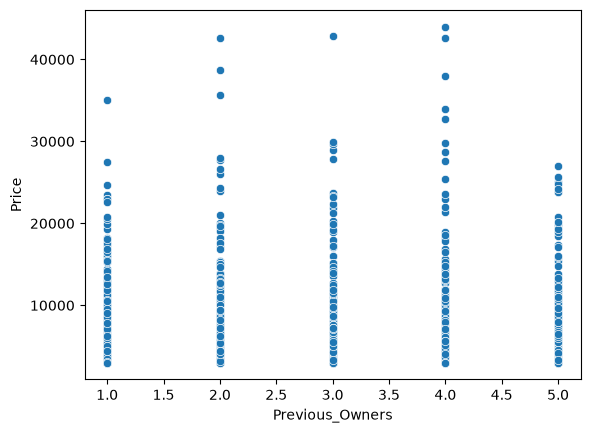

In [48]:
sns.scatterplot(data=df,y='Price',x='Previous_Owners')

<Axes: xlabel='Transmission', ylabel='Price'>

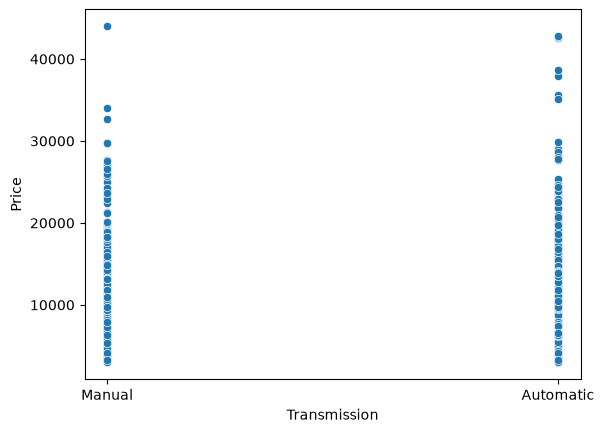

In [49]:
sns.scatterplot(data=df,y='Price',x='Transmission')

<Axes: xlabel='Engine_Size', ylabel='Price'>

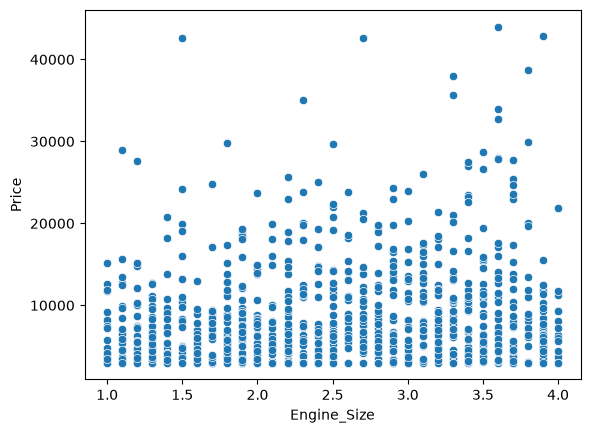

In [50]:
sns.scatterplot(data=df,y='Price',x='Engine_Size')

<Axes: xlabel='Brand', ylabel='Price'>

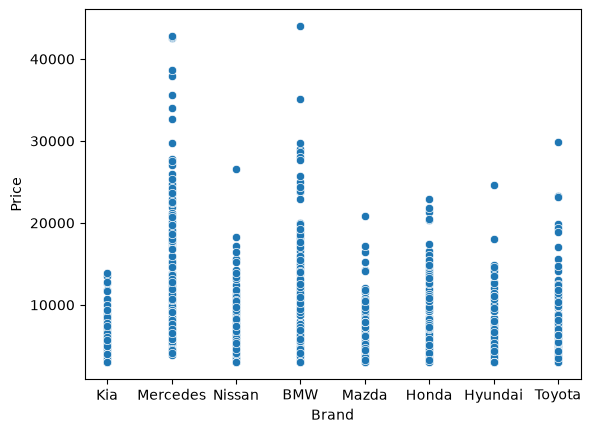

In [51]:
sns.scatterplot(data=df,y='Price',x='Brand')

<Axes: xlabel='Year', ylabel='Price'>

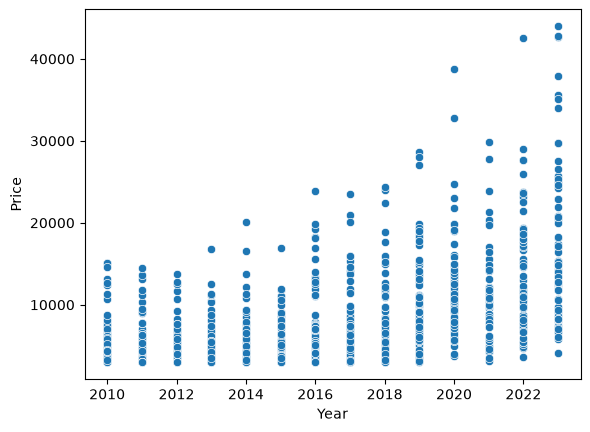

In [52]:
sns.scatterplot(data=df,y='Price',x='Year')

<Axes: xlabel='Mileage', ylabel='Price'>

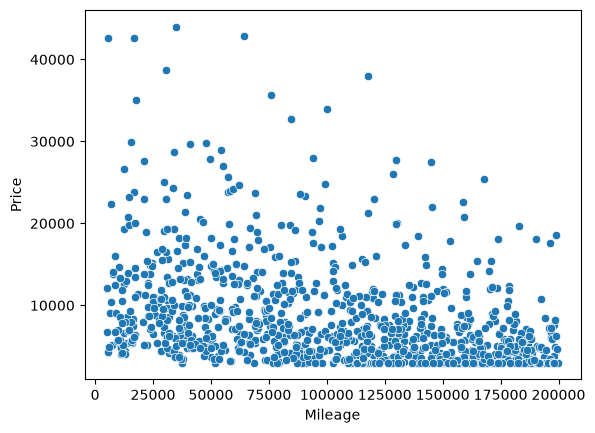

In [53]:
sns.scatterplot(data=df,y='Price',x='Mileage')

<Axes: xlabel='Fuel_Type', ylabel='Price'>

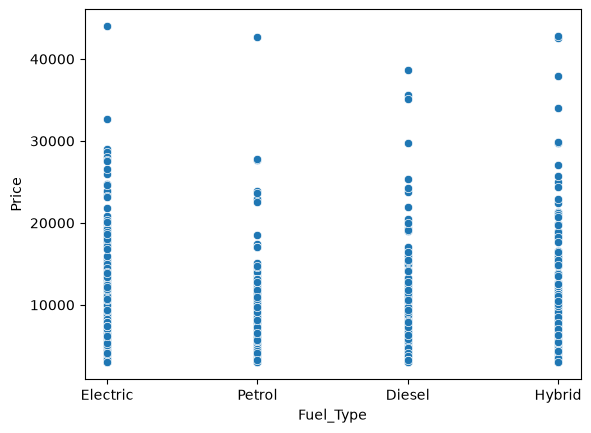

In [54]:
sns.scatterplot(data=df,y='Price',x='Fuel_Type')

(array([551., 203., 113.,  51.,  27.,  16.,   9.,   4.,   2.,   4.]),
 array([ 3000. ,  7099.4, 11198.8, 15298.2, 19397.6, 23497. , 27596.4,
        31695.8, 35795.2, 39894.6, 43994. ]),
 <BarContainer object of 10 artists>)

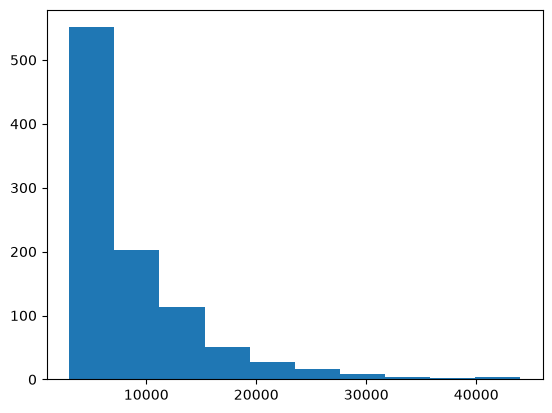

In [55]:
plt.hist(df['Price'],bins=10)

In [56]:
df['Brand'].nunique()


8

In [57]:
df['Fuel_Type'].nunique()


4

In [58]:
df['Transmission'].nunique() 


2

In [59]:
from sklearn.preprocessing import OneHotEncoder

oh = OneHotEncoder(
    sparse_output=False,
    drop='first',
    handle_unknown='ignore'
).set_output(transform='pandas')

for i in ['Brand', 'Fuel_Type', 'Transmission']:
    temp = oh.fit_transform(df[[i]])
    df = pd.concat([df.drop(columns=[i]), temp], axis=1)

In [60]:
df.head()

,Year,Mileage,Engine_Size,Previous_Owners,Price,Brand_Honda,Brand_Hyundai,Brand_Kia,Brand_Mazda,Brand_Mercedes,Brand_Nissan,Brand_Toyota,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Manual
0,2015,110373,2.5,2,3000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,2010,186144,1.3,5,4844,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
2,2018,29574,2.6,1,6628,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0
3,2010,139502,2.4,4,3000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2014,148748,3.5,1,6451,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [61]:
df.dtypes

Year                     int64
Mileage                  int64
Engine_Size            float64
Previous_Owners          int64
Price                    int64
Brand_Honda            float64
Brand_Hyundai          float64
Brand_Kia              float64
Brand_Mazda            float64
Brand_Mercedes         float64
Brand_Nissan           float64
Brand_Toyota           float64
Fuel_Type_Electric     float64
Fuel_Type_Hybrid       float64
Fuel_Type_Petrol       float64
Transmission_Manual    float64
dtype: object

In [62]:
X = df.drop('Price',axis = 1)
y = df['Price']

In [63]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.1,random_state=42)

In [64]:
scaler = StandardScaler()

In [65]:
X_train[['Mileage']] = scaler.fit_transform(
    X_train[['Mileage']]
)

X_test[['Mileage']] = scaler.transform(
    X_test[['Mileage']]
)

In [66]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [67]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

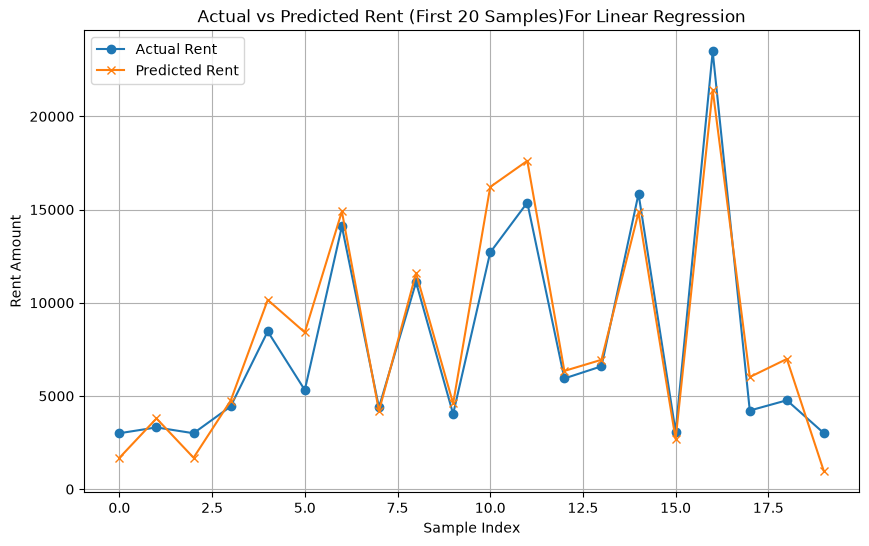

  7%|▋         | 1/15 [00:00<00:01,  7.64it/s]

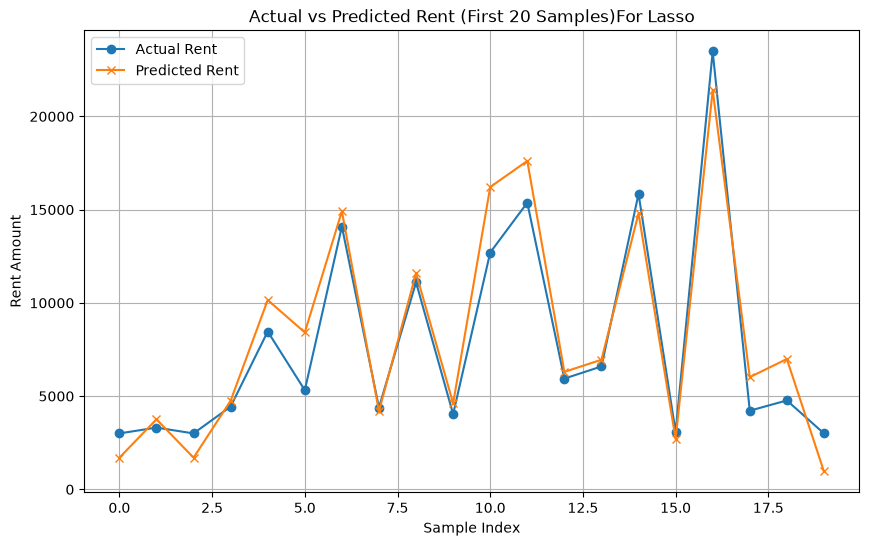

 13%|█▎        | 2/15 [00:00<00:01,  7.73it/s]

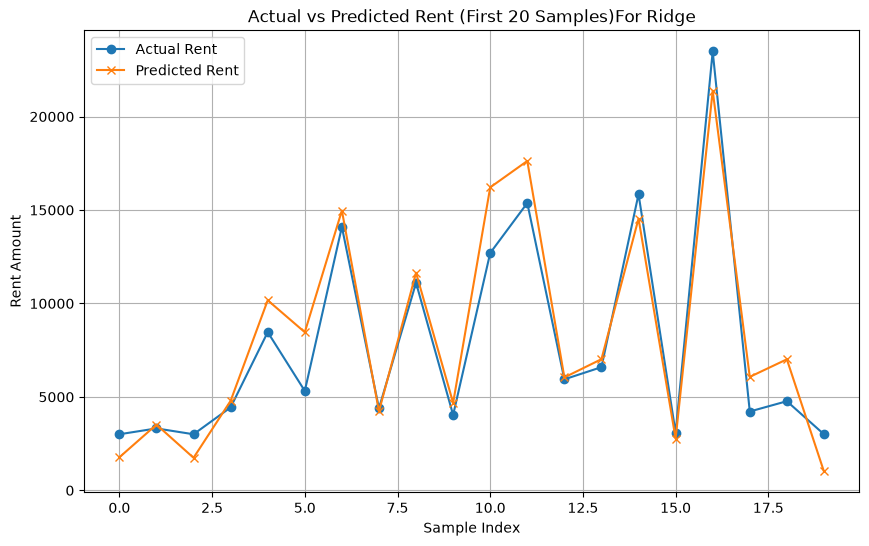

 20%|██        | 3/15 [00:00<00:01,  7.97it/s]

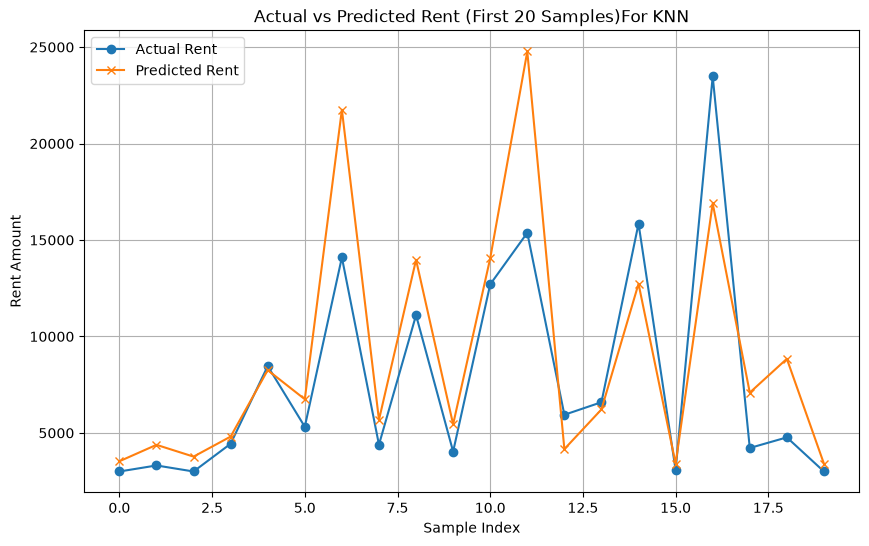

 27%|██▋       | 4/15 [00:00<00:01,  7.87it/s]

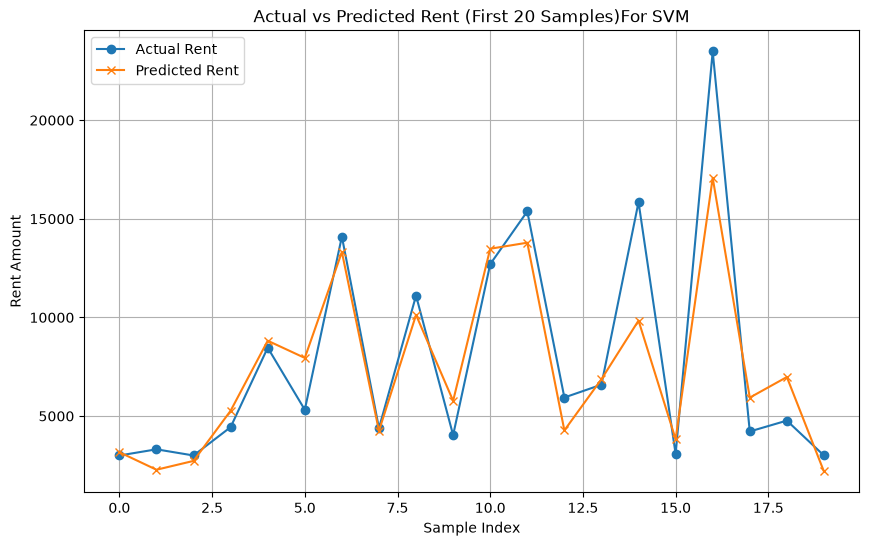

 33%|███▎      | 5/15 [00:00<00:01,  7.43it/s]

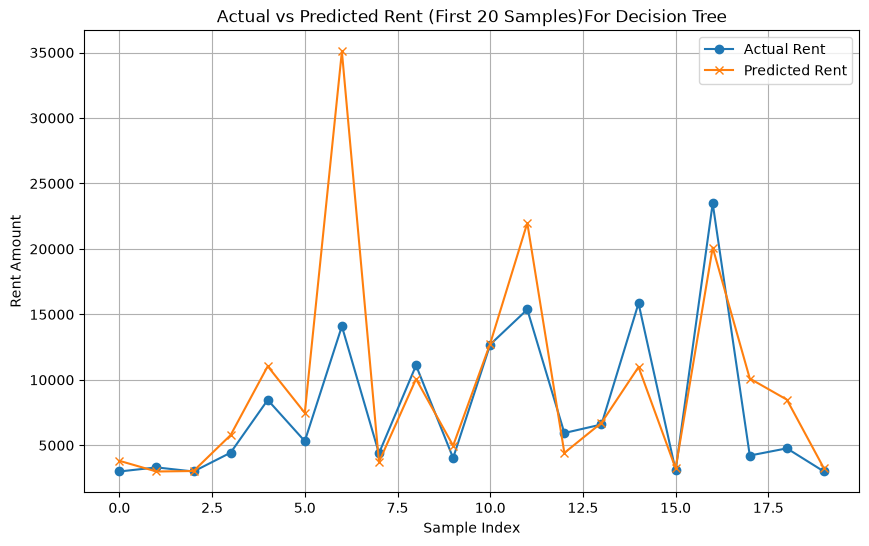

 40%|████      | 6/15 [00:00<00:01,  6.84it/s]

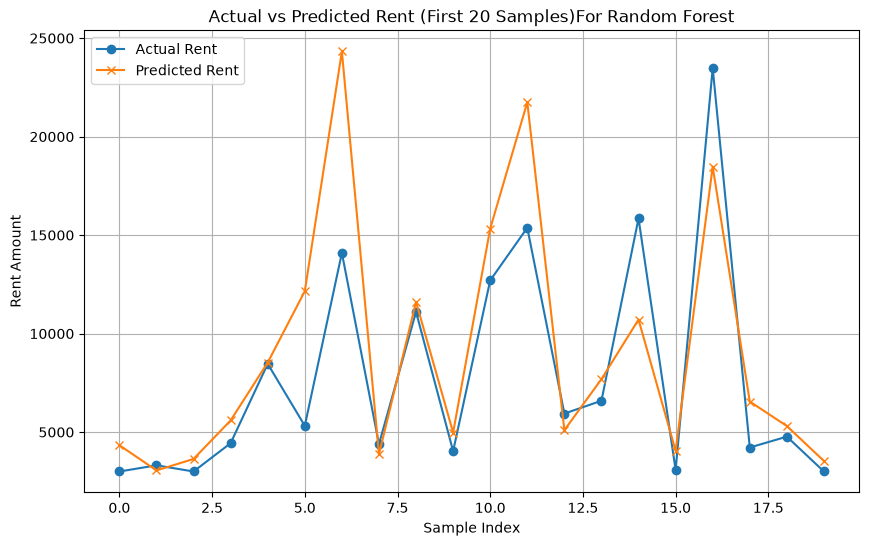

 47%|████▋     | 7/15 [00:01<00:01,  5.86it/s]

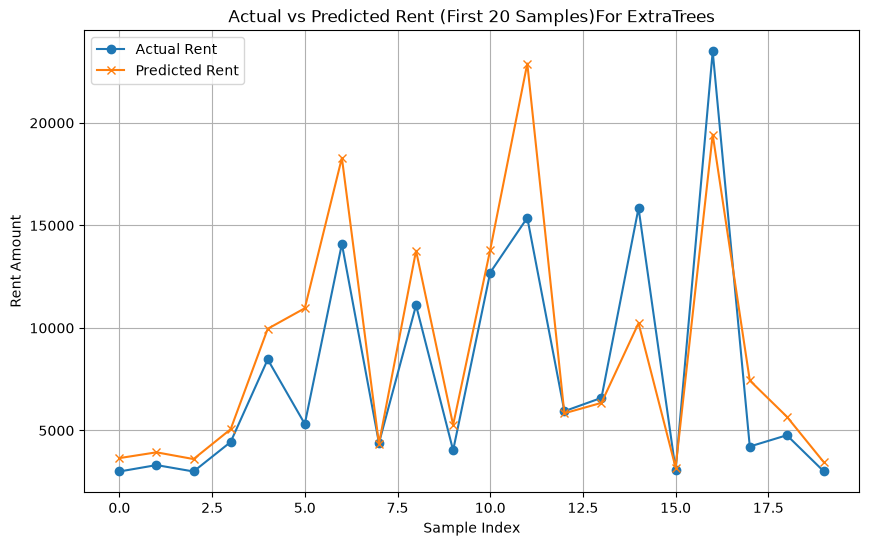

 53%|█████▎    | 8/15 [00:01<00:01,  4.36it/s]

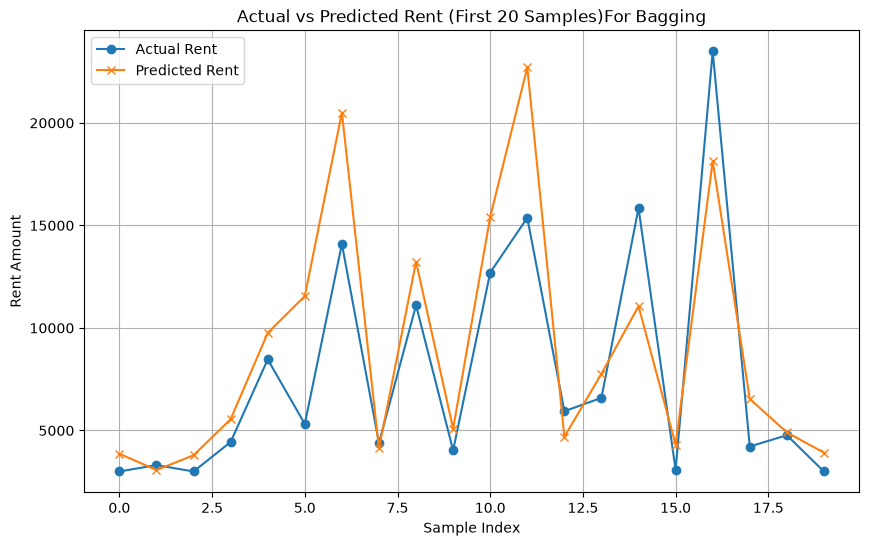

 60%|██████    | 9/15 [00:01<00:01,  3.93it/s]

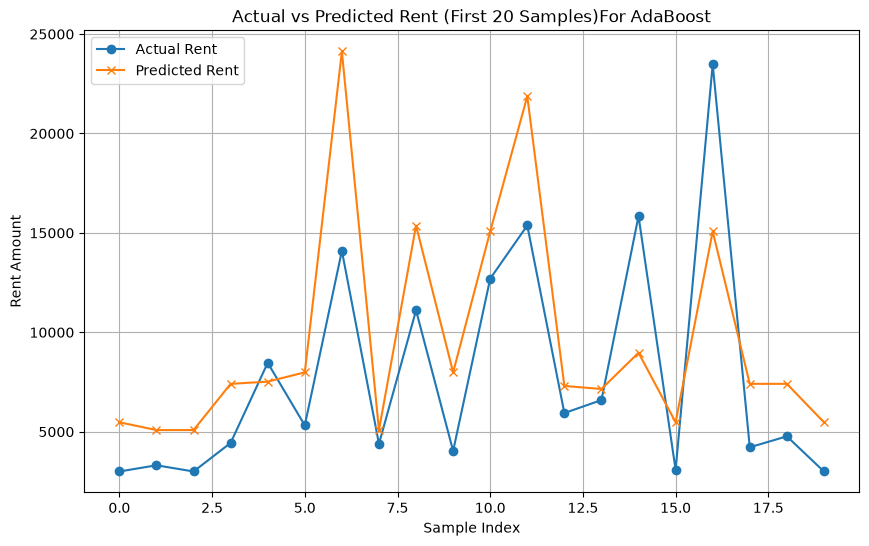

 67%|██████▋   | 10/15 [00:01<00:01,  4.33it/s]

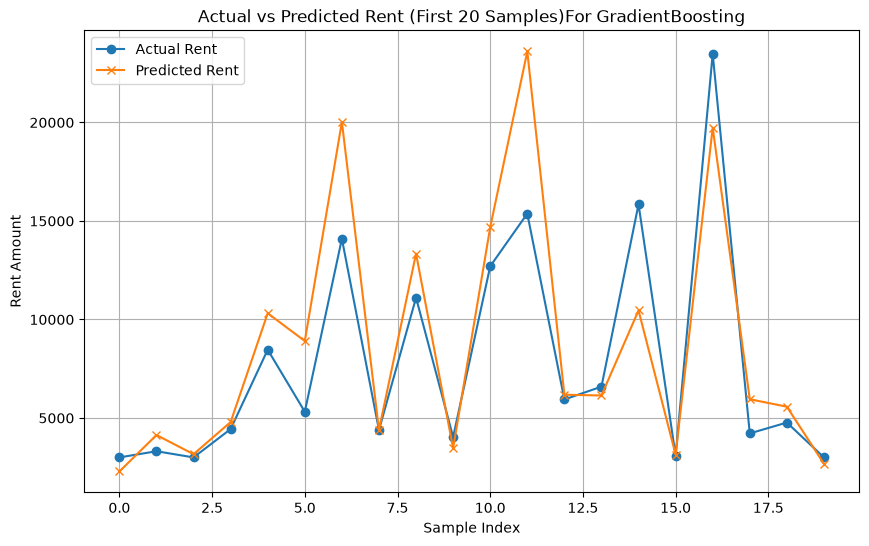

 73%|███████▎  | 11/15 [00:02<00:00,  4.26it/s]

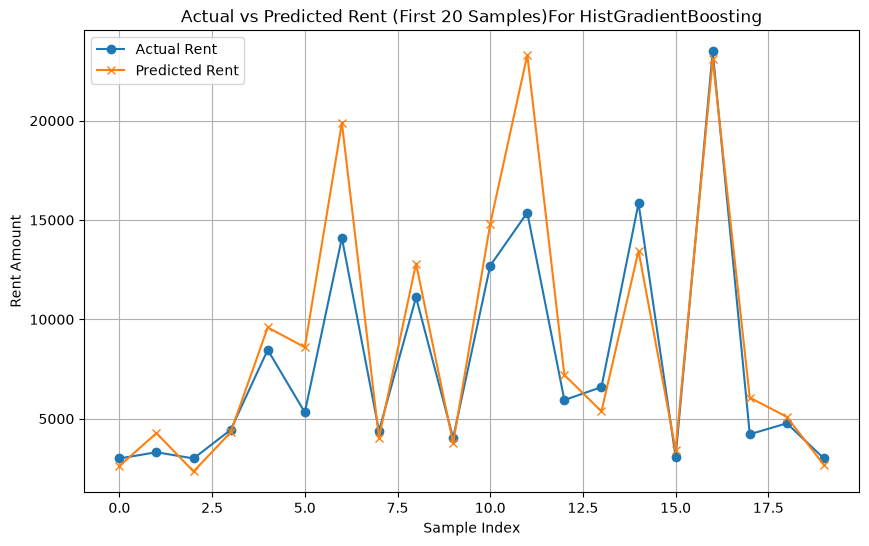

 80%|████████  | 12/15 [00:04<00:02,  1.24it/s]

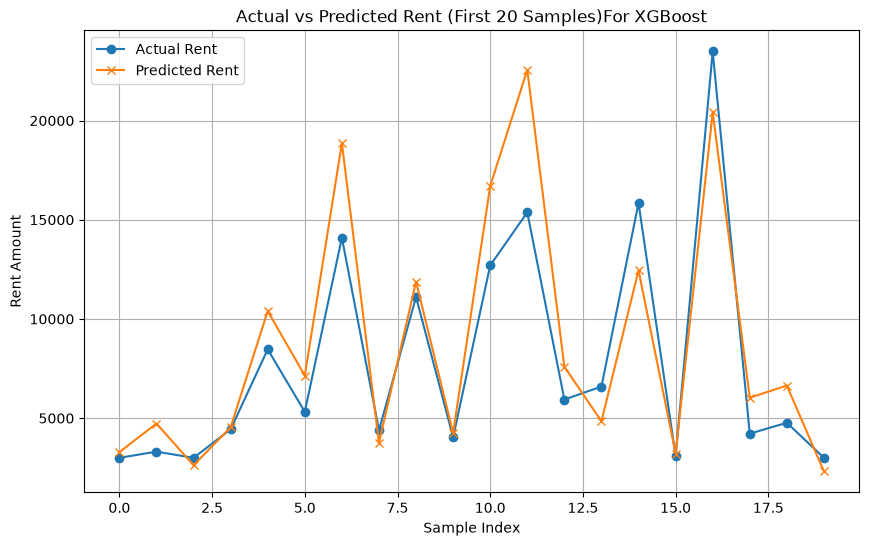

 87%|████████▋ | 13/15 [00:04<00:01,  1.56it/s]

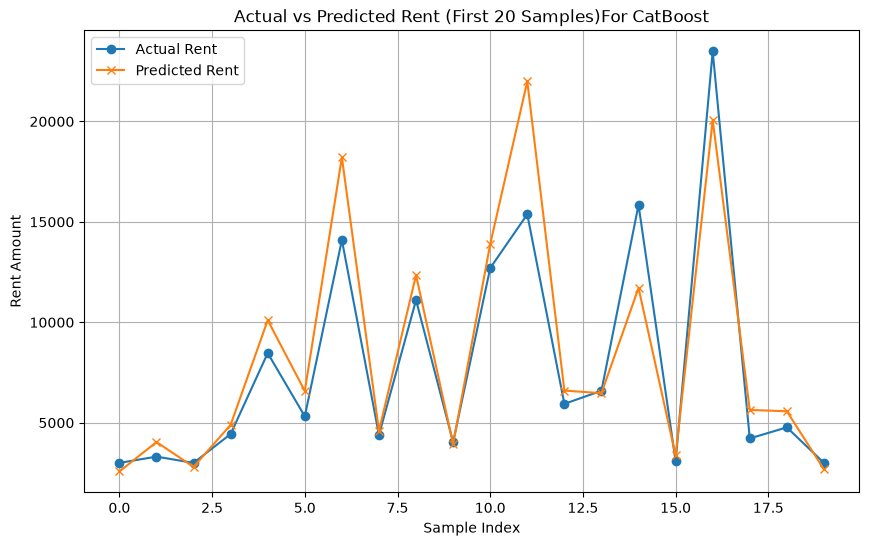

 93%|█████████▎| 14/15 [00:04<00:00,  1.79it/s]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000104 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 330
[LightGBM] [Info] Number of data points in the train set: 882, number of used features: 15
[LightGBM] [Info] Start training from score 8388.839002
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


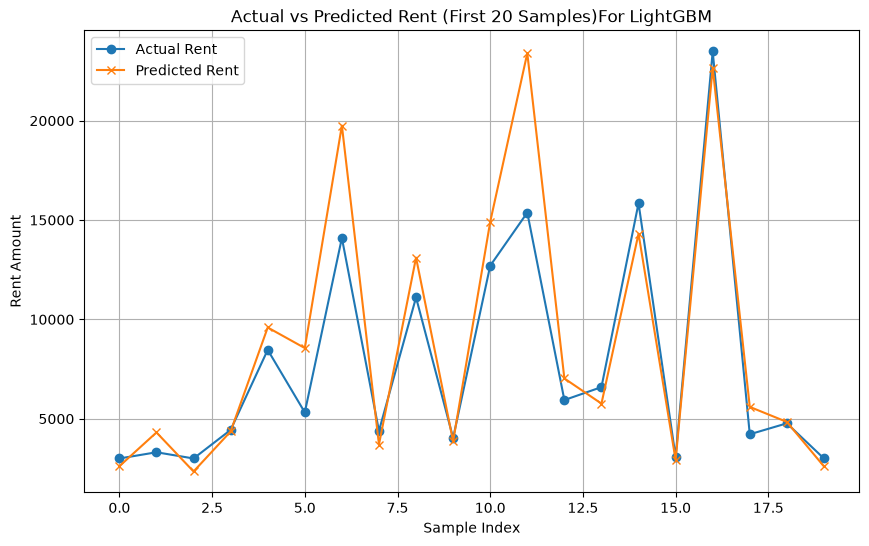

100%|██████████| 15/15 [00:05<00:00,  2.96it/s]


In [68]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [69]:
results_df = pd.DataFrame(errors).T
display(results_df)

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Linear Regression,2067.113958,2176.844168,8.539831e+06,1.239311e+07,2922.298853,3520.385484,0.774433,0.753076
Lasso,2066.630446,2178.721127,8.540148e+06,1.241922e+07,2922.353119,3524.092008,0.774425,0.752556
Ridge,2066.567475,2189.773701,8.552066e+06,1.257058e+07,2924.391612,3545.500997,0.774110,0.749540
KNN,1909.903855,2739.506122,7.722565e+06,1.962894e+07,2778.950317,4430.455596,0.796020,0.608907
SVM,2062.516755,2317.134984,1.276052e+07,1.921869e+07,3572.186439,4383.912266,0.662950,0.617081
Decision Tree,496.957078,3199.990630,9.582224e+05,2.970899e+07,978.888370,5450.595528,0.974690,0.408069
Random Forest,912.840376,2494.851115,1.794684e+06,1.731334e+07,1339.658337,4160.929852,0.952596,0.655044
ExtraTrees,0.000000,2338.406939,0.000000e+00,1.507001e+07,0.000000,3882.010840,1.000000,0.699741
Bagging,904.772796,2555.768670,1.723230e+06,1.656826e+07,1312.718716,4070.412430,0.954483,0.669889
AdaBoost,2743.771779,3560.615127,1.171798e+07,2.271455e+07,3423.152801,4765.978727,0.690487,0.547428
